<a href="https://colab.research.google.com/github/Arish3955/Resume-Screening-/blob/main/resume_screening.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re
import pickle
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

warnings.filterwarnings('ignore')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


# New Section

In [ ]:
df = pd.read_csv('resume_data.csv', engine='python', on_bad_lines='skip')
df = df.rename(columns={'\ufeffjob_position_name': 'job_position_name'})

print("Dataset loaded successfully")
print(f"Total Resumes  : {df.shape[0]}")
print(f"Total Columns  : {df.shape[1]}")
print(f"\nJob Categories : {df['job_position_name'].nunique()}")
print(f"\nAll Job Categories:")
print(df['job_position_name'].value_counts())

Dataset loaded successfully
Total Resumes  : 9544
Total Columns  : 35

Job Categories : 28

All Job Categories:
job_position_name
Project Coordinator (Civil)                                                                342
Site Engineer                                                                              342
Civil Engineer                                                                             342
HR Officer                                                                                 342
Database Administrator (DBA)                                                               341
AI Engineer                                                                                341
Mechanical Designer                                                                        341
Mechanical Engineer                                                                        341
System Administrator (Operation & Maintenance of Server, Storage & Service Desk System)    341
Senior Software

=== BASIC DATASET INFO ===
Total Resumes   : 9544
Total Columns   : 35
Job Categories  : 28

=== MISSING VALUES (Top 10 Columns) ===
languages                              8844
proficiency_levels                     8844
address                                8760
issue_dates                            7536
certification_skills                   7536
certification_providers                7536
expiry_dates                           7536
online_links                           7536
extra_curricular_activity_types        6118
extra_curricular_organization_links    6118
dtype: int64

=== JOB CATEGORY DISTRIBUTION ===
job_position_name
Project Coordinator (Civil)                                                                342
Site Engineer                                                                              342
Civil Engineer                                                                             342
HR Officer                                                                  

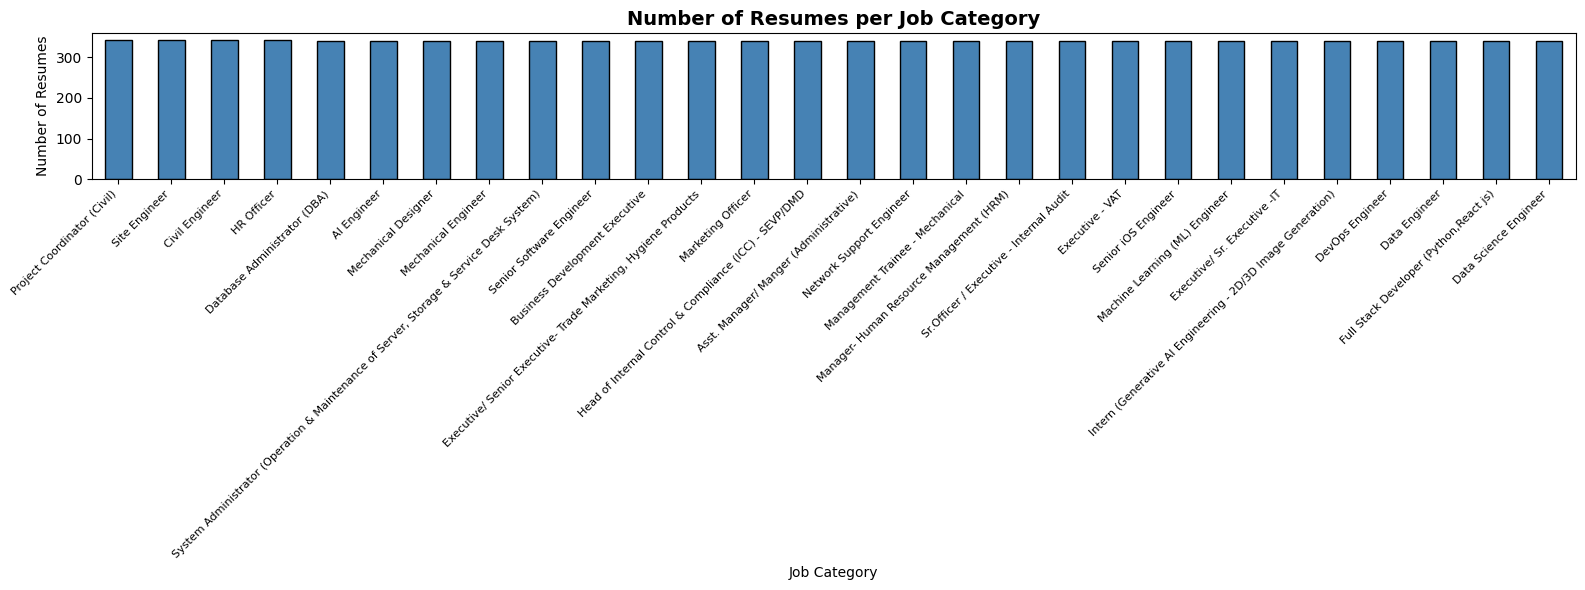


=== SAMPLE RESUME DATA (1st Resume) ===
Job Title     : Senior Software Engineer
Skills        : ['Big Data', 'Hadoop', 'Hive', 'Python', 'Mapreduce', 'Spark', 'Java', 'Machine Learning', 'Cloud', 'Hdfs', 'YARN', 'Core Java', 'Data Science', 'C++', 'Data Structures', 'DBMS', 'RDBMS', 'Informatica', 'Talend', 'Amazon Redshift', 'Microsoft Azure']
Career Obj.   : Big data analytics working and database warehouse manager with robust experience in handling all kinds of data. I have also used multiple cloud infrastructure services and am well acquainted with them. Currently in search of role that offers more of development.
Degree        : ['B.Tech']
Responsiblity : Technical Support
Troubleshooting
Collaboration
Documentation
System Monitoring
Software Deployment
Training & Mentorship
Industry Trends
Field Visits







In [ ]:
#EDA
print("=== BASIC DATASET INFO ===")
print(f"Total Resumes   : {df.shape[0]}")
print(f"Total Columns   : {df.shape[1]}")
print(f"Job Categories  : {df['job_position_name'].nunique()}")


print("\n=== MISSING VALUES (Top 10 Columns) ===")
missing = df.isnull().sum().sort_values(ascending=False).head(10)
print(missing)


print("\n=== JOB CATEGORY DISTRIBUTION ===")
print(df['job_position_name'].value_counts())

plt.figure(figsize=(16, 6))
df['job_position_name'].value_counts().plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)
plt.title('Number of Resumes per Job Category', fontsize=14, fontweight='bold')
plt.xlabel('Job Category')
plt.ylabel('Number of Resumes')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()


print("\n=== SAMPLE RESUME DATA (1st Resume) ===")
print(f"Job Title     : {df['job_position_name'].iloc[0]}")
print(f"Skills        : {df['skills'].iloc[0]}")
print(f"Career Obj.   : {df['career_objective'].iloc[0]}")
print(f"Degree        : {df['degree_names'].iloc[0]}")
print(f"Responsiblity : {df['responsibilities'].iloc[0][:200]}")


In [ ]:


text_columns = [
    'skills',
    'career_objective',
    'degree_names',
    'major_field_of_studies',
    'responsibilities',
    'skills_required',
    'positions',
]

def combine_resume_text(row):
    combined = ''
    for col in text_columns:
        value = str(row[col])
        value = value.replace('[', '').replace(']', '')
        value = value.replace("'", '').replace('"', '')
        value = value.replace('\\n', ' ').replace('None', '')
        combined += ' ' + value
    return combined.strip()

print("Combining columns into 1 text ...")
df['resume_text'] = df.apply(combine_resume_text, axis=1)

print(f"\nTotal resumes processed : {len(df)}")
print(f"\n=== SAMPLE (1st resume, 300 chars) ===")
print(f"Job Title : {df['job_position_name'].iloc[0]}")
print(f"\nCombined Text:")
print(df['resume_text'].iloc[0][:300])

print(f"\n=== SAMPLE (2nd resume, 300 chars) ===")
print(f"Job Title : {df['job_position_name'].iloc[1]}")
print(f"\nCombined Text:")
print(df['resume_text'].iloc[1][:300])

Combining columns into 1 text ...

Total resumes processed : 9544

=== SAMPLE (1st resume, 300 chars) ===
Job Title : Senior Software Engineer

Combined Text:
Big Data, Hadoop, Hive, Python, Mapreduce, Spark, Java, Machine Learning, Cloud, Hdfs, YARN, Core Java, Data Science, C++, Data Structures, DBMS, RDBMS, Informatica, Talend, Amazon Redshift, Microsoft Azure Big data analytics working and database warehouse manager with robust experience in handling 

=== SAMPLE (2nd resume, 300 chars) ===
Job Title : Machine Learning (ML) Engineer

Combined Text:
Data Analysis, Data Analytics, Business Analysis, R, SAS, PowerBi, Tableau, Data Visualization, Business Analytics, Machine Learning Fresher looking to join as a data analyst and junior data scientist. Experienced in creating meaningful data dashboards and evaluation models. B.Sc (Maths), M.Sc (Scie


In [ ]:


stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_resume(text):
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]
    return ' '.join(tokens)

print("Cleaning all resumes — please wait ...")
df['cleaned_resume'] = df['resume_text'].apply(clean_resume)

print(f"\nTotal resumes cleaned : {len(df)}")
print(f"\nAFTER CLEANING (1st resume, 300 chars):")
print(df['cleaned_resume'].iloc[0][:300])
print(f"\nAFTER CLEANING (2nd resume, 300 chars):")
print(df['cleaned_resume'].iloc[1][:300])

Cleaning all resumes — please wait ...

Total resumes cleaned : 9544

AFTER CLEANING (1st resume, 300 chars):
big data hadoop hive python mapreduce spark java machine learning cloud hdfs yarn core java data science data structure dbms rdbms informatica talend amazon redshift microsoft azure big data analytics working database warehouse manager robust experience handling kind data also used multiple cloud in

AFTER CLEANING (2nd resume, 300 chars):
data analysis data analytics business analysis sa powerbi tableau data visualization business analytics machine learning fresher looking join data analyst junior data scientist experienced creating meaningful data dashboard evaluation model math science statistic mathematics statistic machine learni


In [ ]:

def score_to_label(score):
    if score >= 0.75:   return 'High Match'
    elif score >= 0.50: return 'Medium Match'
    else:               return 'Low Match'

df['match_label'] = df['matched_score'].apply(score_to_label)


le = LabelEncoder()
df['label'] = le.fit_transform(df['match_label'])

print("Label Encoding Done ✓")
print(f"\nTotal Categories : {len(le.classes_)}")
print("\nLabel Distribution:")
print(df['match_label'].value_counts())
for i, cat in enumerate(le.classes_):
    print(f"  {i}  →  {cat}")

Label Encoding Done ✓

Total Categories : 3

Label Distribution:
match_label
Medium Match    4110
High Match      3658
Low Match       1776
Name: count, dtype: int64
  0  →  High Match
  1  →  Low Match
  2  →  Medium Match


In [ ]:

X = df['cleaned_resume']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    max_features=20000,
    sublinear_tf=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"\nTraining Matrix Shape : {X_train_tfidf.shape}")
print(f"Testing  Matrix Shape : {X_test_tfidf.shape}")
print(f"\nTraining Set : {len(X_train)} resumes")
print(f"Testing Set  : {len(X_test)}  resumes")


Training Matrix Shape : (7635, 17582)
Testing  Matrix Shape : (1909, 17582)

Training Set : 7635 resumes
Testing Set  : 1909  resumes


In [ ]:
models = {
    'Logistic Regression' : LogisticRegression(
                                max_iter=1000,
                                C=5.0,
                                class_weight='balanced',
                                random_state=42
                            ),
    'SVM'                 : SVC(
                                kernel='linear',
                                C=0.5,
                                probability=True,
                                class_weight='balanced',
                                random_state=42
                            ),
    'Random Forest'       : RandomForestClassifier(
                                n_estimators=200,
                                max_depth=20,
                                min_samples_leaf=5,
                                class_weight='balanced',
                                random_state=42,
                                n_jobs=-1
                            ),
    'KNN'                 : KNeighborsClassifier(n_neighbors=7, metric='cosine'),
    'Naive Bayes'         : MultinomialNB(alpha=0.1),
}

results = {}

print("Training all models — please wait ...\n")
print(f"{'Model':<22}  {'Test Accuracy':>14}  {'Train Accuracy':>15}")
print("-" * 55)

for name, model_instance in models.items():
    model_instance.fit(X_train_tfidf, y_train)
    train_acc = accuracy_score(y_train, model_instance.predict(X_train_tfidf))
    test_acc  = accuracy_score(y_test,  model_instance.predict(X_test_tfidf))
    results[name] = {
        'model'     : model_instance,
        'train_acc' : train_acc,
        'test_acc'  : test_acc
    }
    print(f"{name:<22}  {test_acc*100:>13.2f}%  {train_acc*100:>14.2f}%")

best_name  = max(results, key=lambda k: results[k]['test_acc'])
best_model = results[best_name]['model']


global tfidf, le
global best_model
print("-" * 55)
print(f"\n Best Model    : {best_name}")
print(f"   Test Accuracy : {results[best_name]['test_acc']*100:.2f}%")
print(f"   Train Accuracy: {results[best_name]['train_acc']*100:.2f}%")

Training all models — please wait ...

Model                    Test Accuracy   Train Accuracy
-------------------------------------------------------
Logistic Regression             67.47%           75.42%
SVM                             64.75%           70.81%
Random Forest                   65.43%           73.49%
KNN                             53.06%           64.77%
Naive Bayes                     64.59%           68.80%
-------------------------------------------------------

 Best Model    : Logistic Regression
   Test Accuracy : 67.47%
   Train Accuracy: 75.42%


In [ ]:
from google.colab import drive
import pickle

drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/resume_app', exist_ok=True)

with open('/content/drive/MyDrive/resume_app/model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('/content/drive/MyDrive/resume_app/tfidf.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

with open('/content/drive/MyDrive/resume_app/label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

print("✅ All files saved to Google Drive!")

Mounted at /content/drive
✅ All files saved to Google Drive!


In [ ]:
!pip install flask pyngrok pdfplumber -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 69.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 48.3 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pickle
import re
import pdfplumber
import nltk
from flask import Flask, request, jsonify
import threading
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

# ── Load Models ─────────────────────────────────────────────────────
with open('/content/drive/MyDrive/resume_app/model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('/content/drive/MyDrive/resume_app/tfidf.pkl', 'rb') as f:
    tfidf = pickle.load(f)
with open('/content/drive/MyDrive/resume_app/label_encoder.pkl', 'rb') as f:
    le = pickle.load(f)
with open('/content/drive/MyDrive/resume_app/job_model.pkl', 'rb') as f:
    job_model = pickle.load(f)
with open('/content/drive/MyDrive/resume_app/tfidf_job.pkl', 'rb') as f:
    tfidf_job = pickle.load(f)
with open('/content/drive/MyDrive/resume_app/le_job.pkl', 'rb') as f:
    le_job = pickle.load(f)

# ── Text Cleaning ───────────────────────────────────────────────────
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return ' '.join(tokens)

# ── Flask App ───────────────────────────────────────────────────────
app = Flask(__name__)

HTML_PAGE = """
<!DOCTYPE html>
<html>
<head>
  <title>Resume Job Matcher</title>
  <style>
    * { box-sizing: border-box; margin: 0; padding: 0; }
    body {
      font-family: 'Segoe UI', sans-serif;
      background: #f0f4ff;
      display: flex;
      justify-content: center;
      align-items: center;
      min-height: 100vh;
      padding: 40px 16px;
    }
    .card {
      background: white;
      padding: 40px;
      border-radius: 16px;
      box-shadow: 0 4px 24px rgba(0,0,0,0.1);
      width: 520px;
      text-align: center;
    }
    h1 { font-size: 24px; color: #2d3a8c; margin-bottom: 8px; }
    p.sub { color: #666; font-size: 14px; margin-bottom: 28px; }
    .upload-area {
      border: 2px dashed #a0aec0;
      border-radius: 12px;
      padding: 32px;
      cursor: pointer;
      margin-bottom: 20px;
      transition: border-color 0.2s;
    }
    .upload-area:hover { border-color: #2d3a8c; }
    .upload-area p { color: #888; font-size: 14px; margin-top: 10px; }
    .upload-area span { font-size: 36px; }
    input[type="file"] { display: none; }
    button {
      background: #2d3a8c;
      color: white;
      border: none;
      padding: 12px 32px;
      border-radius: 8px;
      font-size: 16px;
      cursor: pointer;
      width: 100%;
      transition: background 0.2s;
    }
    button:hover { background: #1a2460; }

    /* ── Top Result ── */
    .top-result {
      margin-top: 24px;
      background: #ebf8ff;
      border: 1px solid #90cdf4;
      border-radius: 12px;
      padding: 20px;
      display: none;
    }
    .top-result h2 { color: #2b6cb0; font-size: 16px; margin-bottom: 6px; }
    .top-result .job { font-size: 22px; font-weight: bold; color: #2d3a8c; margin-bottom: 8px; }
    .badge {
      display: inline-block;
      font-size: 13px;
      font-weight: bold;
      padding: 3px 14px;
      border-radius: 20px;
    }
    .high   { background: #c6f6d5; color: #276749; }
    .medium { background: #fefcbf; color: #744210; }
    .low    { background: #fed7d7; color: #822727; }

    /* ── Other Jobs ── */
    .other-jobs {
      margin-top: 20px;
      text-align: left;
      display: none;
    }
    .other-jobs h3 {
      font-size: 15px;
      color: #444;
      margin-bottom: 14px;
      text-align: center;
    }
    .job-row { margin-bottom: 14px; }
    .job-row .job-name {
      font-size: 13px;
      color: #2d3a8c;
      font-weight: 600;
      margin-bottom: 4px;
      display: flex;
      justify-content: space-between;
    }
    .job-row .job-name span { color: #888; font-weight: normal; }
    .bar-bg {
      background: #e2e8f0;
      border-radius: 999px;
      height: 10px;
      width: 100%;
      overflow: hidden;
    }
    .bar-fill {
      height: 10px;
      border-radius: 999px;
      background: linear-gradient(90deg, #2d3a8c, #63b3ed);
      width: 0%;
      transition: width 0.8s ease;
    }

    .loading { display: none; color: #888; margin-top: 16px; font-size: 14px; }
    .filename { font-size: 13px; color: #2d3a8c; margin-top: 8px; }
    .error { color: #e53e3e; margin-top: 16px; font-size: 14px; display: none; }
  </style>
</head>
<body>
  <div class="card">
    <h1>📄 Resume Job Matcher</h1>
    <p class="sub">Upload your resume PDF and we'll suggest the best job for you</p>

    <div class="upload-area" onclick="document.getElementById('fileInput').click()">
      <span>📂</span>
      <p>Click to upload your Resume (PDF only)</p>
      <div class="filename" id="filename"></div>
    </div>

    <input type="file" id="fileInput" accept=".pdf" onchange="showFilename(this)">
    <button onclick="uploadResume()">Analyse Resume</button>

    <div class="loading" id="loading">⏳ Analysing your resume...</div>
    <div class="error" id="error"></div>

    <!-- Top Result -->
    <div class="top-result" id="topResult">
      <h2>🏆 Best Job Match For You</h2>
      <div class="job" id="jobTitle"></div>
      <div class="badge" id="matchLabel"></div>
    </div>

    <!-- Other Jobs -->
    <div class="other-jobs" id="otherJobs">
      <h3>📊 All Job Match Scores</h3>
      <div id="jobBars"></div>
    </div>
  </div>

  <script>
    function showFilename(input) {
      const name = input.files[0]?.name || '';
      document.getElementById('filename').textContent = name ? '✅ ' + name : '';
    }

    async function uploadResume() {
      const file = document.getElementById('fileInput').files[0];
      if (!file) { showError('Please select a PDF file first!'); return; }

      document.getElementById('loading').style.display = 'block';
      document.getElementById('topResult').style.display = 'none';
      document.getElementById('otherJobs').style.display = 'none';
      document.getElementById('error').style.display = 'none';
      document.getElementById('jobBars').innerHTML = '';

      const formData = new FormData();
      formData.append('resume', file);

      try {
        const res = await fetch('/predict', { method: 'POST', body: formData });
        const data = await res.json();
        document.getElementById('loading').style.display = 'none';

        if (data.error) { showError(data.error); return; }

        // Top result
        document.getElementById('jobTitle').textContent = '💼 ' + data.job_title;
        const matchEl = document.getElementById('matchLabel');
        matchEl.textContent = data.match_label;
        matchEl.className = 'badge ' + (
          data.match_label === 'High Match' ? 'high' :
          data.match_label === 'Medium Match' ? 'medium' : 'low'
        );
        document.getElementById('topResult').style.display = 'block';

        // Job bars
        const barsDiv = document.getElementById('jobBars');
        data.all_jobs.forEach((item, i) => {
          const row = document.createElement('div');
          row.className = 'job-row';
          row.innerHTML = `
            <div class="job-name">
              ${i + 1}. ${item.job}
              <span>${item.percent}%</span>
            </div>
            <div class="bar-bg">
              <div class="bar-fill" id="bar-${i}"></div>
            </div>
          `;
          barsDiv.appendChild(row);
        });

        document.getElementById('otherJobs').style.display = 'block';

        // Animate bars after render
        setTimeout(() => {
          data.all_jobs.forEach((item, i) => {
            document.getElementById('bar-' + i).style.width = item.percent + '%';
          });
        }, 100);

      } catch (e) {
        document.getElementById('loading').style.display = 'none';
        showError('Something went wrong. Please try again.');
      }
    }

    function showError(msg) {
      const el = document.getElementById('error');
      el.textContent = msg;
      el.style.display = 'block';
    }
  </script>
</body>
</html>
"""

@app.route('/')
def index():
    return HTML_PAGE

@app.route('/predict', methods=['POST'])
def predict():
    if 'resume' not in request.files:
        return jsonify({'error': 'No file uploaded'})

    file = request.files['resume']
    if file.filename == '':
        return jsonify({'error': 'Empty file'})

    try:
        # Extract text from PDF
        with pdfplumber.open(file) as pdf:
            text = ' '.join(page.extract_text() or '' for page in pdf.pages)

        if not text.strip():
            return jsonify({'error': 'Could not extract text from PDF'})

        cleaned = clean_text(text)

        # Predict job title + all probabilities
        job_input = tfidf_job.transform([cleaned])
        probs = job_model.predict_proba(job_input)[0]
        job_names = le_job.classes_

        # Sort all jobs by probability
        job_scores = sorted(
            zip(job_names, probs),
            key=lambda x: x[1],
            reverse=True
        )

        top_job = job_scores[0][0]

        # Build all jobs list (top 10)
        all_jobs = [
            {
                'job': job,
                'percent': round(float(prob) * 100, 1)
            }
            for job, prob in job_scores[:10]
        ]

        # Predict match label
        match_input = tfidf.transform([cleaned])
        match_pred = model.predict(match_input)[0]
        match_label = le.inverse_transform([match_pred])[0]

        return jsonify({
            'job_title': top_job,
            'match_label': match_label,
            'all_jobs': all_jobs
        })

    except Exception as e:
        return jsonify({'error': str(e)})

# ── Run Flask ───────────────────────────────────────────────────────
def run_app():
    app.run(port=5000)

threading.Thread(target=run_app).start()
print("✅ Flask is running!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


✅ Flask is running!


In [ ]:
print("✅ Port 5000 management adjusted!")

✅ Port 5000 management adjusted!


In [ ]:


from pyngrok import ngrok

ngrok.set_auth_token("3FyYuwkvsTv68aAyb8yAQbX38FY_79RHpr4ZtC59QV9DJ8Jap")

public_url = ngrok.connect(5000)
print(f"✅ App is live at: {public_url}")
print("👆 Click that link to open your Resume Matcher!")

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


✅ App is live at: NgrokTunnel: "https://shorty-earphone-confirm.ngrok-free.dev" -> "http://localhost:5000"
👆 Click that link to open your Resume Matcher!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Job Title Model
X_job = df['cleaned_resume']
y_job = df['job_position_name'].str.strip()

le_job = LabelEncoder()
y_job_encoded = le_job.fit_transform(y_job)

X_train_j, X_test_j, y_train_j, y_test_j = train_test_split(
    X_job, y_job_encoded, test_size=0.2, random_state=42, stratify=y_job_encoded
)

tfidf_job = TfidfVectorizer(max_features=20000, sublinear_tf=True, ngram_range=(1,2), min_df=2)
X_train_j_tfidf = tfidf_job.fit_transform(X_train_j)
X_test_j_tfidf  = tfidf_job.transform(X_test_j)

job_model = LogisticRegression(max_iter=1000, C=5.0, random_state=42)
job_model.fit(X_train_j_tfidf, y_train_j)

acc = accuracy_score(y_test_j, job_model.predict(X_test_j_tfidf))
print(f"✅ Job Title Model Trained! Accuracy: {acc*100:.2f}%")
print(f"   Jobs it can predict: {list(le_job.classes_)}")

# Save to Drive
import pickle
with open('/content/drive/MyDrive/resume_app/job_model.pkl', 'wb') as f:
    pickle.dump(job_model, f)
with open('/content/drive/MyDrive/resume_app/tfidf_job.pkl', 'wb') as f:
    pickle.dump(tfidf_job, f)
with open('/content/drive/MyDrive/resume_app/le_job.pkl', 'wb') as f:
    pickle.dump(le_job, f)

print("✅ Job model saved to Drive!")

✅ Job Title Model Trained! Accuracy: 100.00%
   Jobs it can predict: ['AI Engineer', 'Asst. Manager/ Manger (Administrative)', 'Business Development Executive', 'Civil Engineer', 'Data Engineer', 'Data Science Engineer', 'Database Administrator (DBA)', 'DevOps Engineer', 'Executive - VAT', 'Executive/ Senior Executive- Trade Marketing, Hygiene Products', 'Executive/ Sr. Executive -IT', 'Full Stack Developer (Python,React js)', 'HR Officer', 'Head of Internal Control & Compliance (ICC) - SEVP/DMD', 'Intern (Generative AI Engineering - 2D/3D Image Generation)', 'Machine Learning (ML) Engineer', 'Management Trainee - Mechanical', 'Manager- Human Resource Management (HRM)', 'Marketing Officer', 'Mechanical Designer', 'Mechanical Engineer', 'Network Support Engineer', 'Project Coordinator (Civil)', 'Senior Software Engineer', 'Senior iOS Engineer', 'Site Engineer', 'Sr.Officer / Executive - Internal Audit', 'System Administrator (Operation & Maintenance of Server, Storage & Service Desk Sys